In [9]:
# import ipyparallel as ipp
# rc = ipp.Cluster(engines="mpi", n=2).start_and_connect_sync(activate=True)

In [25]:
import os
os.environ["CC"] = "/usr/bin/clang"
os.environ["CXX"] = "/usr/bin/clang++"
os.environ["PATH"] = (
    "/usr/bin:/bin:/usr/sbin:/sbin:"
    + os.environ["PATH"]
)

from msfem_new import MsFEM, EllipticProblemData, oversampling, plot_function, plot_function_warped, plot_oversampling
from mpi4py import MPI
import dolfinx.mesh as mesh
import dolfinx.fem as fem
import pyvista
import numpy as np
import ufl

pyvista.OFF_SCREEN = True

r = 3  # H = 2**(-r)
k = 0.5

comm = MPI.COMM_WORLD
nx = int(2**(r))
ny = nx
refinement_levels = int(7-r)
num_layers = int(k * 2**(7-r))
epsilon = 5e-2

coarse_mesh = mesh.create_unit_square(
    comm=comm,
    nx=nx,
    ny=ny,
    cell_type=mesh.CellType.triangle,
    ghost_mode=mesh.GhostMode.none)

tdim = coarse_mesh.topology.dim
data = EllipticProblemData(epsilon)

msfem = MsFEM(
    coarse_mesh,
    data,
    refinement_levels,
    num_layers,
)

c = 10
local_cell_list = msfem.coarse_to_fine_cells.find(c)
oversampled_cell_list = oversampling(msfem.fine_mesh, num_layers, local_cell_list)
oversampled_mesh, _, _, _ = mesh.create_submesh(msfem.fine_mesh, tdim, oversampled_cell_list)
plot_oversampling(coarse_mesh, msfem.fine_mesh, oversampled_mesh)

In [27]:
def error_norm(u, uh, norm_type='L2'):
    error = ufl.inner(u - uh, u - uh) * ufl.dx 
    if norm_type == 'H1':
        error += ufl.inner(ufl.grad(u - uh), ufl.grad(u - uh)) * ufl.dx
    return ufl.sqrt(fem.assemble_scalar(fem.form(error)))

In [33]:
def test(r, k, T, Nt=8):
    nx = int(2**(r))
    ny = nx
    refinement_levels = int(6-r)
    num_layers = int(k * 2**(6-r))
    epsilon = 5e-2

    coarse_mesh = mesh.create_unit_square(
        comm=comm,
        nx=nx,
        ny=ny,
        cell_type=mesh.CellType.triangle,
        ghost_mode=mesh.GhostMode.none)
    
    data = EllipticProblemData(epsilon)

    msfem = MsFEM(
        coarse_mesh,
        data,
        refinement_levels,
        num_layers,
    )

    if T == np.inf:
        is_parabolic = False
    else:
        is_parabolic = True

    K, F = msfem.offline(is_parabolic, T, Nt)
    u_ms = msfem.online(K, F)

    u_ex = msfem.data.exact_solution(u_ms.function_space)

    l2_error = error_norm(u_ex, u_ms)
    h1_error = error_norm(u_ex, u_ms, "H1")

    return l2_error, h1_error

In [34]:
Ts = [np.inf, 1/16, 1/4, 1, 4, 16]
ks = [0, 1/2, 1, 3/2]
rs = [2, 3, 4, 5]

In [35]:
# import time
# import pandas as pd

# records = []
# num_tests = len(rs) * len(ks) * len(Ts)
# counter = 0

# for r in rs:
#     for k in ks:
#         for T in Ts:
#             counter += 1
#             start = time.perf_counter()

#             print(
#                 f"[{counter}/{num_tests}] "
#                 f"r={r}, k={k}, T={T}"
#             )

#             try:
#                 l2_error, h1_error = test(r, k, T, Nt=16)

#                 record = {
#                     "r": r,
#                     "k": k,
#                     "T": T,
#                     "Nt": 1,
#                     "l2_error": l2_error,
#                     "h1_error": h1_error,
#                     "elapsed_seconds": time.perf_counter() - start,
#                     "status": "success",
#                     "message": "",
#                 }

#             except Exception as error:
#                 record = {
#                     "r": r,
#                     "k": k,
#                     "T": T,
#                     "Nt": 1,
#                     "l2_error": float("nan"),
#                     "h1_error": float("nan"),
#                     "elapsed_seconds": time.perf_counter() - start,
#                     "status": "failed",
#                     "message": str(error),
#                 }

#             records.append(record)

#             results = pd.DataFrame.from_records(records)
#             results.to_csv("msfem_convergence_results.csv", index=False)

# results


In [36]:
Ts = np.logspace(-4, 4, 9)
l2_errors = []
h1_errors = []

for T in Ts:
    l2_error, h1_error = test(2, 0.5, T, Nt=4)
    l2_errors.append(l2_error)
    h1_errors.append(h1_error)

ld: warning: duplicate -rpath '/opt/anaconda3/envs/fenicsx-env/lib' ignored
ld: warning: duplicate -rpath '/opt/anaconda3/envs/fenicsx-env/lib' ignored
ld: warning: duplicate -rpath '/opt/anaconda3/envs/fenicsx-env/lib' ignored
ld: warning: duplicate -rpath '/opt/anaconda3/envs/fenicsx-env/lib' ignored
ld: warning: duplicate -rpath '/opt/anaconda3/envs/fenicsx-env/lib' ignored
ld: warning: duplicate -rpath '/opt/anaconda3/envs/fenicsx-env/lib' ignored
ld: warning: duplicate -rpath '/opt/anaconda3/envs/fenicsx-env/lib' ignored
ld: warning: duplicate -rpath '/opt/anaconda3/envs/fenicsx-env/lib' ignored
ld: warning: duplicate -rpath '/opt/anaconda3/envs/fenicsx-env/lib' ignored
ld: warning: duplicate -rpath '/opt/anaconda3/envs/fenicsx-env/lib' ignored
ld: warning: duplicate -rpath '/opt/anaconda3/envs/fenicsx-env/lib' ignored
ld: warning: duplicate -rpath '/opt/anaconda3/envs/fenicsx-env/lib' ignored
ld: warning: duplicate -rpath '/opt/anaconda3/envs/fenicsx-env/lib' ignored
ld: warning:

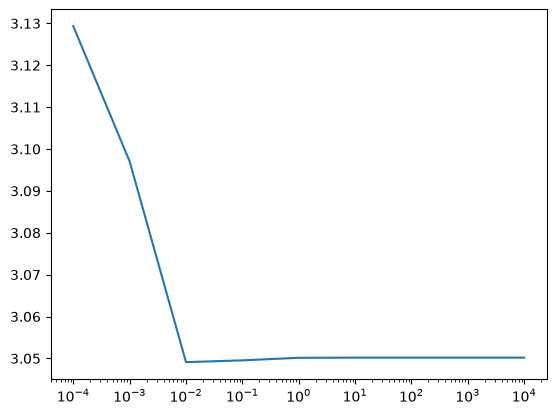

In [22]:
import matplotlib.pyplot as plt

plt.semilogx(Ts, h1_errors)

In [23]:
h1_errors

[3.1293305789816346,
 3.0970319360421694,
 3.049114614061873,
 3.049543726272091,
 3.050150541665245,
 3.0501874417516985,
 3.050187451249033,
 3.0501874512490335,
 3.0501874512490335]